Project Overview 


Data Loading and Understanding

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "/Users/sanath/Downloads/default of credit card clients.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (30000, 25)


Data Quality Assessment

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_AMT3        

In [14]:
df.isnull().sum()

ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df["ID"].duplicated().sum()

np.int64(0)

In [17]:
df.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


Understanding Credit Card Default

In [18]:
df["default payment next month"].value_counts()

default payment next month
0    23364
1     6636
Name: count, dtype: int64

In [19]:
target = "default payment next month"

default_summary = df[target].value_counts().reset_index()

default_summary.columns = ["default_status", "customers"]

default_summary["percentage"] = (
    default_summary["customers"] / len(df) * 100
).round(2)

default_summary

,default_status,customers,percentage
0,0,23364,77.88
1,1,6636,22.12


In [20]:
df.groupby(target)["LIMIT_BAL"].agg(
    ["count", "mean", "median"]
)

,count,mean,median
default payment next month,,,
0,23364,178099.726074,150000.0
1,6636,130109.656420,90000.0


Repayment Behaviour Analysis

In [21]:
# Create credit limit groups
bins = [0, 50000, 100000, 200000, 300000, 500000, 1000001]

labels = [
    "0-50K",
    "50K-100K",
    "100K-200K",
    "200K-300K",
    "300K-500K",
    "500K-1M"
]

df["credit_limit_group"] = pd.cut(
    df["LIMIT_BAL"],
    bins=bins,
    labels=labels,
    right=True
)

# Calculate default rates by credit limit
credit_risk = df.groupby(
    "credit_limit_group",
    observed=False
).agg(
    total_customers=("ID", "count"),
    defaulted_customers=("default payment next month", "sum"),
    average_credit_limit=("LIMIT_BAL", "mean")
)

credit_risk["default_rate"] = (
    credit_risk["defaulted_customers"] /
    credit_risk["total_customers"] * 100
).round(2)

credit_risk

,total_customers,defaulted_customers,average_credit_limit,default_rate
credit_limit_group,,,,
0-50K,7676,2440,35204.794164,31.79
50K-100K,4822,1244,80759.021153,25.80
100K-200K,7880,1535,158327.411168,19.48
200K-300K,5059,812,250430.915201,16.05
300K-500K,4357,582,396386.890062,13.36
500K-1M,206,23,598398.058252,11.17


In [26]:
repayment_columns = [
    "PAY_6", "PAY_5", "PAY_4",
    "PAY_3", "PAY_2", "PAY_0"
]

repayment_months = {
    "PAY_6": "April",
    "PAY_5": "May",
    "PAY_4": "June",
    "PAY_3": "July",
    "PAY_2": "August",
    "PAY_0": "September"
}

repayment_results = []

for column in repayment_columns:
    monthly_result = df.groupby(column).agg(
        total_customers=(target, "count"),
        defaulted_customers=(target, "sum")
    )

    monthly_result["default_rate"] = (
        monthly_result["defaulted_customers"] /
        monthly_result["total_customers"] * 100
    ).round(2)

    monthly_result["month"] = repayment_months[column]
    monthly_result["repayment_status"] = monthly_result.index

    repayment_results.append(monthly_result.reset_index(drop=True))

repayment_analysis = pd.concat(
    repayment_results,
    ignore_index=True
)

repayment_analysis = repayment_analysis[
    [
        "month",
        "repayment_status",
        "total_customers",
        "defaulted_customers",
        "default_rate"
    ]
].sort_values(
    ["month", "repayment_status"]
).reset_index(drop=True)

display(repayment_analysis)


,month,repayment_status,total_customers,defaulted_customers,default_rate
0,April,-2,4895,981,20.04
1,April,-1,5740,975,16.99
2,April,0,16286,3069,18.84
3,April,2,2766,1401,50.65
4,April,3,184,118,64.13
...,...,...,...,...,...
59,September,4,76,52,68.42
60,September,5,26,13,50.00
61,September,6,11,6,54.55
62,September,7,9,7,77.78


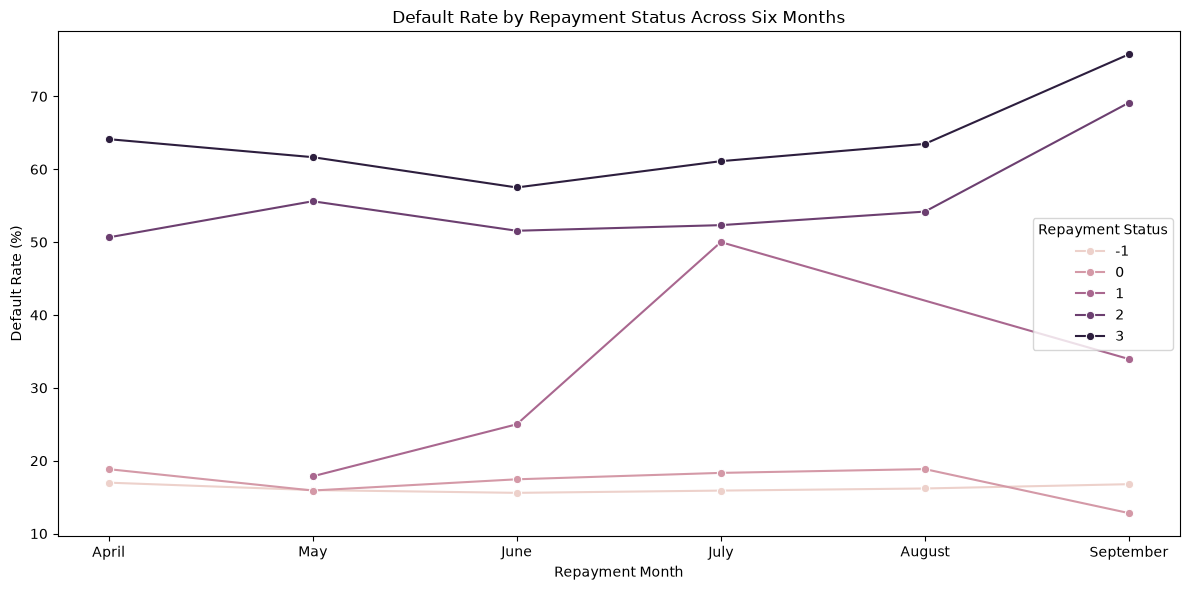

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Keep common repayment statuses for a clearer comparison
common_statuses = [-1, 0, 1, 2, 3]

chart_data = repayment_analysis[
    repayment_analysis["repayment_status"].isin(common_statuses)
].copy()

# Arrange months chronologically
month_order = [
    "April", "May", "June",
    "July", "August", "September"
]

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=chart_data,
    x="month",
    y="default_rate",
    hue="repayment_status",
    hue_order=common_statuses,
    marker="o",
    sort=False
)

plt.title("Default Rate by Repayment Status Across Six Months")
plt.xlabel("Repayment Month")
plt.ylabel("Default Rate (%)")
plt.xticks(range(len(month_order)), month_order)
plt.legend(title="Repayment Status")
plt.tight_layout()
plt.show()

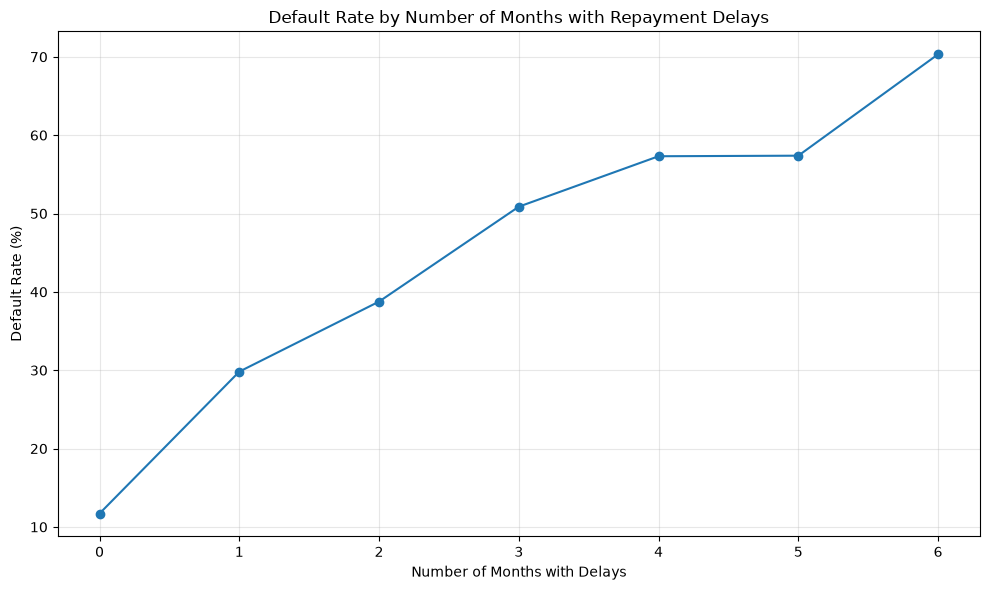

In [31]:
import matplotlib.pyplot as plt

plot_data = delay_risk.reset_index()

plt.figure(figsize=(10, 6))

plt.plot(
    plot_data["months_with_delay"],
    plot_data["default_rate"],
    marker="o"
)

plt.title("Default Rate by Number of Months with Repayment Delays")
plt.xlabel("Number of Months with Delays")
plt.ylabel("Default Rate (%)")
plt.xticks(range(7))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [32]:
risk_comparison = df.pivot_table(
    index="credit_limit_group",
    columns="months_with_delay",
    values="default payment next month",
    aggfunc="mean",
    observed=False
) * 100

risk_comparison.round(2)

months_with_delay,0,1,2,3,4,5,6
credit_limit_group,,,,,,,
0-50K,16.67,33.81,41.51,52.99,58.37,54.79,70.59
50K-100K,12.02,33.10,43.94,50.41,58.41,61.29,67.85
100K-200K,10.89,27.08,36.57,48.03,53.07,65.45,70.51
200K-300K,10.21,26.32,32.56,48.48,61.02,43.48,77.11
300K-500K,9.01,27.76,25.37,49.21,50.00,63.64,71.05
500K-1M,6.82,25.00,66.67,50.00,33.33,0.00,50.00


In [33]:
sample_sizes = df.pivot_table(
    index="credit_limit_group",
    columns="months_with_delay",
    values="ID",
    aggfunc="count",
    observed=False
)

sample_sizes

months_with_delay,0,1,2,3,4,5,6
credit_limit_group,,,,,,,
0-50K,3990,1201,730,519,478,146,612
50K-100K,2912,710,371,242,214,62,311
100K-200K,5464,1215,443,229,179,55,295
200K-300K,3858,722,215,99,59,23,83
300K-500K,3531,562,134,63,18,11,38
500K-1M,176,16,6,2,3,1,2


Customer Financial Behaviour

In [34]:
comparison = risk_comparison[[0, 6]].copy()

comparison.columns = [
    "default_rate_no_delays",
    "default_rate_six_delays"
]

comparison["difference_percentage_points"] = (
    comparison["default_rate_six_delays"]
    - comparison["default_rate_no_delays"]
).round(2)

comparison["customers_no_delays"] = sample_sizes[0]
comparison["customers_six_delays"] = sample_sizes[6]

comparison

,default_rate_no_delays,default_rate_six_delays,difference_percentage_points,customers_no_delays,customers_six_delays
credit_limit_group,,,,,
0-50K,16.666667,70.588235,53.92,3990,612
50K-100K,12.019231,67.845659,55.83,2912,311
100K-200K,10.889458,70.508475,59.62,5464,295
200K-300K,10.212545,77.108434,66.90,3858,83
300K-500K,9.005947,71.052632,62.05,3531,38
500K-1M,6.818182,50.000000,43.18,176,2


Customer Segmentation

In [35]:
# Compare September bills and payments by default status

bill_payment_summary = df.groupby(
    "default payment next month"
).agg(
    customers=("ID", "count"),
    average_bill=("BILL_AMT1", "mean"),
    average_payment=("PAY_AMT1", "mean"),
    median_bill=("BILL_AMT1", "median"),
    median_payment=("PAY_AMT1", "median")
).round(2)

bill_payment_summary

,customers,average_bill,average_payment,median_bill,median_payment
default payment next month,,,,,
0,23364,51994.23,6307.34,23119.5,2459.5
1,6636,48509.16,3397.04,20185.0,1636.0


In [36]:
# Create a copy to avoid changing the original dataset
payment_analysis = df.copy()

# Calculate payment as a percentage of the bill
payment_analysis["payment_to_bill_ratio"] = np.where(
    payment_analysis["BILL_AMT1"] > 0,
    (payment_analysis["PAY_AMT1"] /
     payment_analysis["BILL_AMT1"]) * 100,
    np.nan
)

# Compare payment behaviour by default status
payment_ratio_summary = payment_analysis.groupby(
    target
).agg(
    customers=("ID", "count"),
    average_payment_ratio=("payment_to_bill_ratio", "mean"),
    median_payment_ratio=("payment_to_bill_ratio", "median")
).round(2)

payment_ratio_summary

,customers,average_payment_ratio,median_payment_ratio
default payment next month,,,
0,23364,202.68,6.58
1,6636,88.04,5.03


In [37]:
bill_columns = [
    "BILL_AMT6", "BILL_AMT5", "BILL_AMT4",
    "BILL_AMT3", "BILL_AMT2", "BILL_AMT1"
]

bill_summary = df.groupby(target)[bill_columns].mean().round(2)

bill_summary

,BILL_AMT6,BILL_AMT5,BILL_AMT4,BILL_AMT3,BILL_AMT2,BILL_AMT1
default payment next month,,,,,,
0,39042.27,40530.45,43611.17,47533.37,49717.44,51994.23
1,38271.44,39540.19,42036.95,45181.60,47283.62,48509.16


In [38]:
payment_columns = [
    "PAY_AMT6", "PAY_AMT5", "PAY_AMT4",
    "PAY_AMT3", "PAY_AMT2", "PAY_AMT1"
]

payment_summary = df.groupby(target)[payment_columns].mean().round(2)

payment_summary

,PAY_AMT6,PAY_AMT5,PAY_AMT4,PAY_AMT3,PAY_AMT2,PAY_AMT1
default payment next month,,,,,,
0,5719.37,5248.22,5300.53,5753.50,6640.47,6307.34
1,3441.48,3219.14,3155.63,3367.35,3388.65,3397.04


In [39]:
df["repayment_segment"] = pd.cut(
    df["months_with_delay"],
    bins=[-1, 0, 1, 3, 6],
    labels=["No Delay", "Low Risk", "Medium Risk", "High Risk"]
)

segment_summary = df.groupby(
    "repayment_segment",
    observed=False
).agg(
    customers=("ID", "count"),
    defaulted_customers=(target, "sum"),
    average_credit_limit=("LIMIT_BAL", "mean")
)

segment_summary["default_rate"] = (
    segment_summary["defaulted_customers"]
    / segment_summary["customers"] * 100
).round(2)

segment_summary.round(2)

,customers,defaulted_customers,average_credit_limit,default_rate
repayment_segment,,,,
No Delay,19931,2334,187259.43,11.71
Low Risk,4426,1320,158388.16,29.82
Medium Risk,3053,1323,116005.90,43.33
High Risk,2590,1659,91532.82,64.05


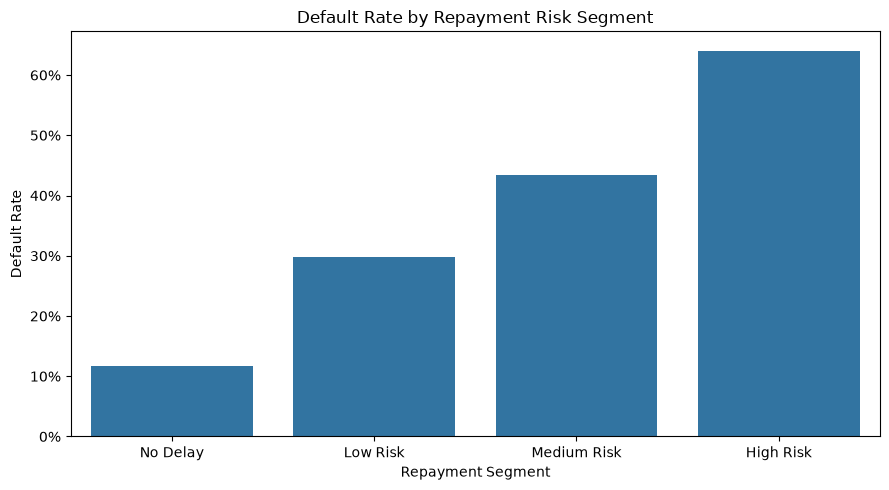

In [40]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="repayment_segment",
    y=target,
    estimator="mean",
    errorbar=None
)

plt.title("Default Rate by Repayment Risk Segment")
plt.xlabel("Repayment Segment")
plt.ylabel("Default Rate")
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y * 100:.0f}%")
)

plt.tight_layout()
plt.show()

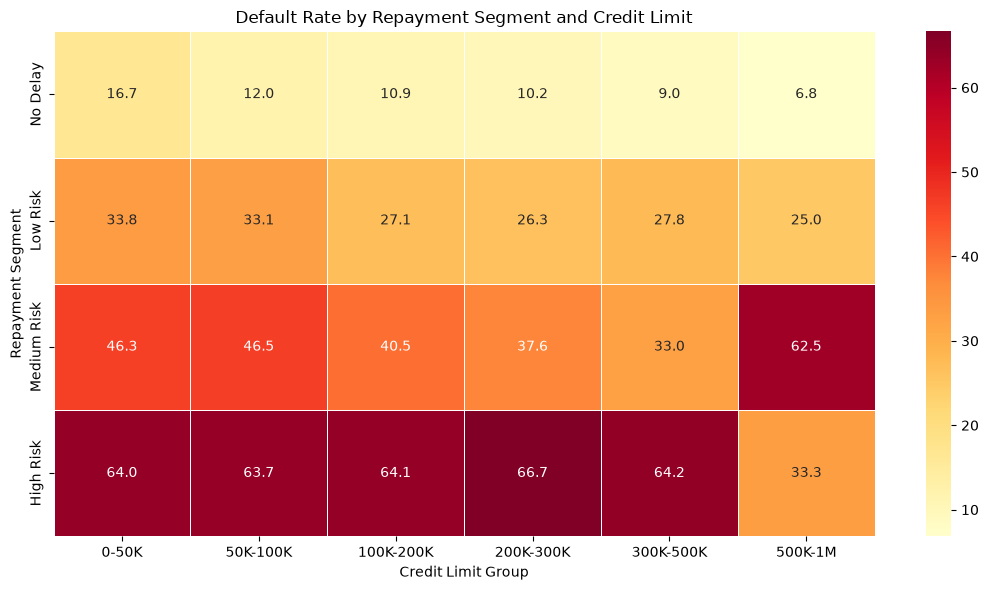

In [41]:
segment_credit_pivot = df.pivot_table(
    index="repayment_segment",
    columns="credit_limit_group",
    values=target,
    aggfunc="mean",
    observed=False
) * 100

plt.figure(figsize=(11, 6))

sns.heatmap(
    segment_credit_pivot,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Default Rate by Repayment Segment and Credit Limit")
plt.xlabel("Credit Limit Group")
plt.ylabel("Repayment Segment")

plt.tight_layout()
plt.show()

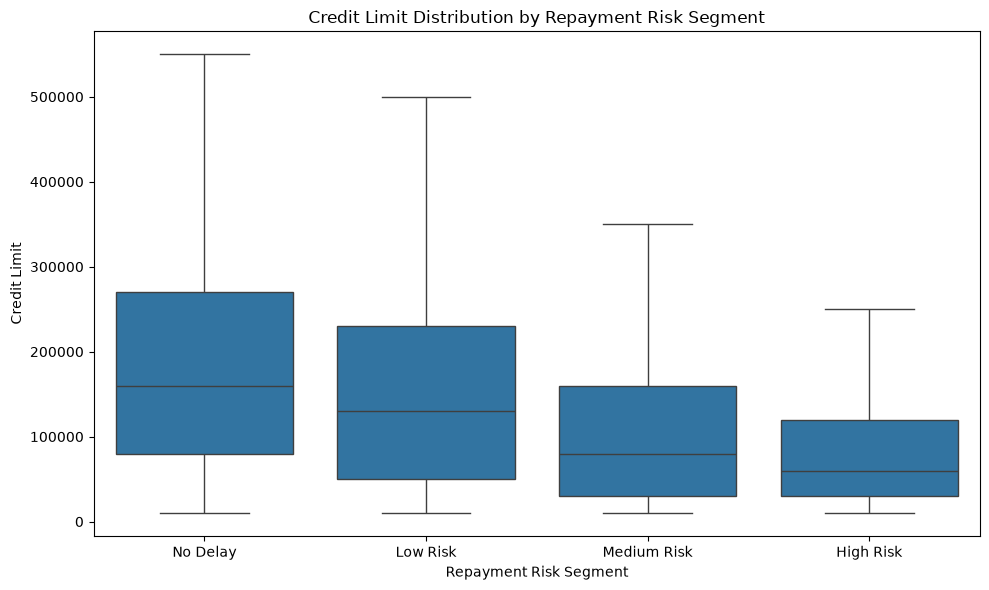

In [42]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="repayment_segment",
    y="LIMIT_BAL",
    showfliers=False
)

plt.title("Credit Limit Distribution by Repayment Risk Segment")
plt.xlabel("Repayment Risk Segment")
plt.ylabel("Credit Limit")

plt.tight_layout()
plt.show()

In [43]:
df.groupby("repayment_segment", observed=False)["LIMIT_BAL"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

,count,mean,median,min,max
repayment_segment,,,,,
No Delay,19931,187259.43,160000.0,10000,1000000
Low Risk,4426,158388.16,130000.0,10000,750000
Medium Risk,3053,116005.90,80000.0,10000,620000
High Risk,2590,91532.82,60000.0,10000,600000


In [44]:
df["age_group"] = pd.cut(
    df["AGE"],
    bins=[20, 25, 35, 45, 55, 100],
    labels=["Below 25", "25-35", "36-45", "46-55", "Above 55"]
)

In [45]:
age_segment_summary = df.pivot_table(
    index="repayment_segment",
    columns="age_group",
    values=target,
    aggfunc="mean",
    observed=False
) * 100

age_segment_summary.round(2)

age_group,Below 25,25-35,36-45,46-55,Above 55
repayment_segment,,,,,
No Delay,13.40,10.41,12.03,13.65,13.23
Low Risk,34.18,26.62,30.07,32.05,43.08
Medium Risk,47.16,40.34,44.19,47.10,38.78
High Risk,60.79,61.67,66.72,68.95,68.97


Statistical Analysis and Model Validation

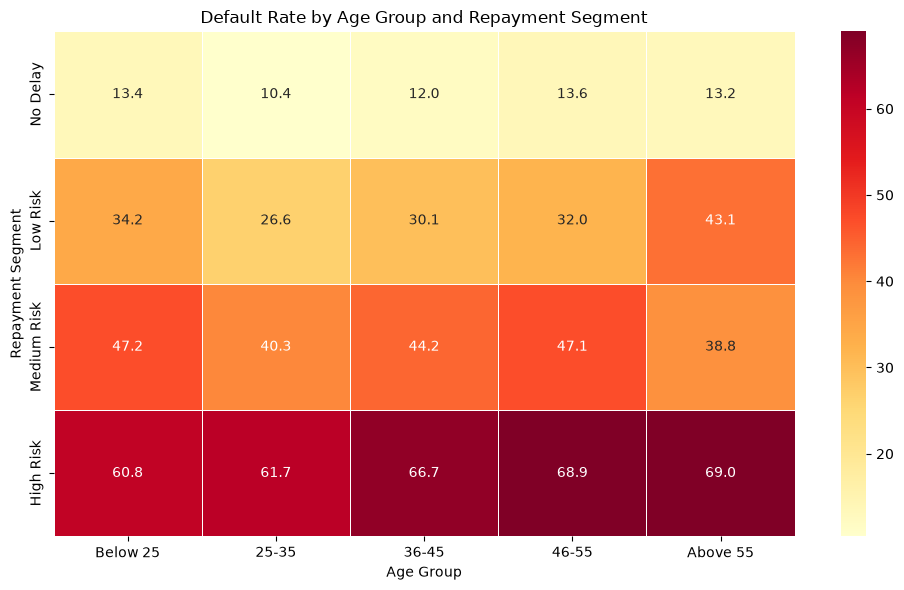

In [46]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    age_segment_summary,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Default Rate by Age Group and Repayment Segment")
plt.xlabel("Age Group")
plt.ylabel("Repayment Segment")

plt.tight_layout()
plt.show()

In [47]:
correlation_columns = [
    "LIMIT_BAL",
    "AGE",
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6",
    "months_with_delay",
    "BILL_AMT1",
    "PAY_AMT1",
    target
]

correlation_matrix = df[correlation_columns].corr(
    method="pearson"
)

correlation_matrix[target].sort_values(
    ascending=False
).round(3)

default payment next month    1.000
months_with_delay             0.398
PAY_0                         0.325
PAY_2                         0.264
PAY_3                         0.235
PAY_4                         0.217
PAY_5                         0.204
PAY_6                         0.187
AGE                           0.014
BILL_AMT1                    -0.020
PAY_AMT1                     -0.073
LIMIT_BAL                    -0.154
Name: default payment next month, dtype: float64

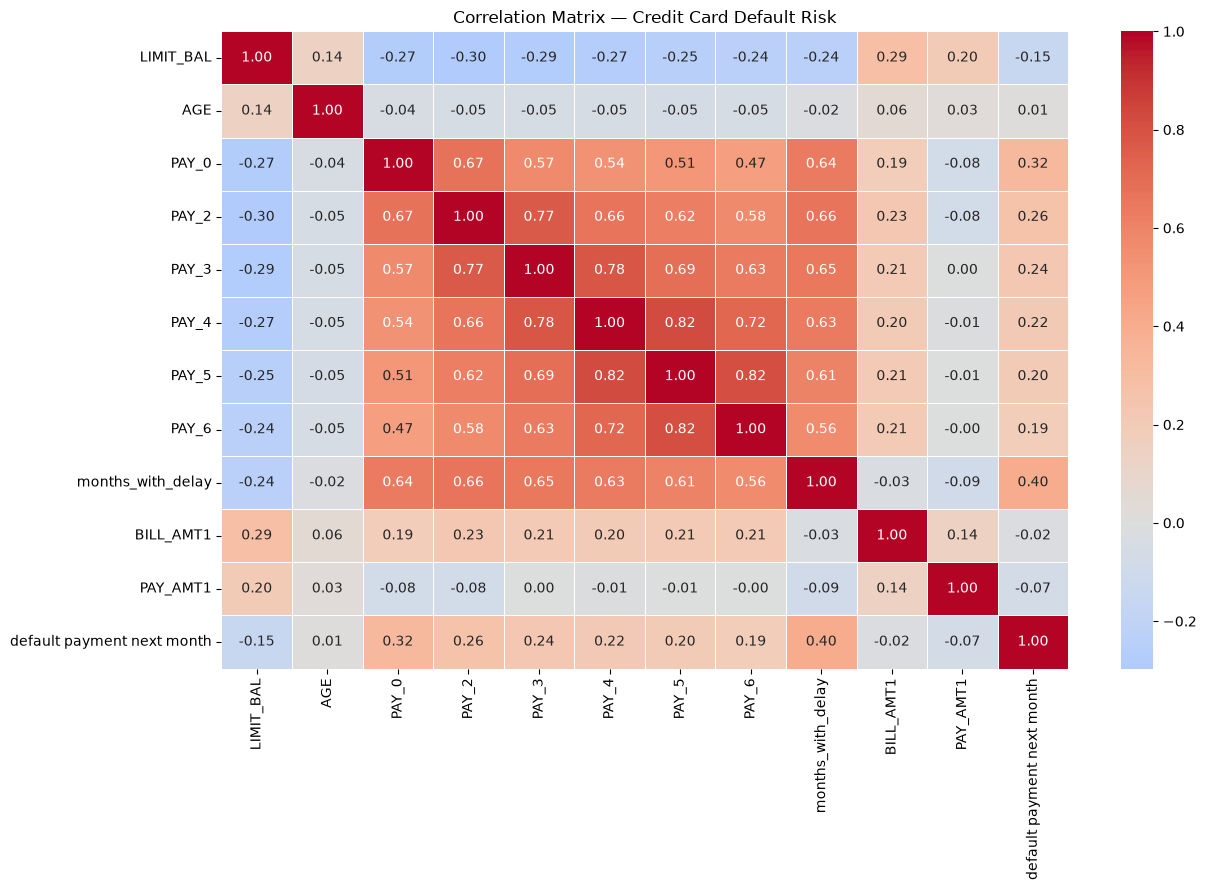

In [48]:
plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix — Credit Card Default Risk")
plt.tight_layout()
plt.show()

In [49]:
from scipy.stats import mannwhitneyu

no_default = df.loc[df[target] == 0, "LIMIT_BAL"]
defaulted = df.loc[df[target] == 1, "LIMIT_BAL"]

statistic, p_value = mannwhitneyu(
    no_default,
    defaulted,
    alternative="two-sided"
)

print("Mann-Whitney U Statistic:", statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Result: Statistically significant difference.")
else:
    print("Result: No statistically significant difference.")

Mann-Whitney U Statistic: 95786286.5
P-value: 1.2255485818223303e-189
Result: Statistically significant difference.


In [50]:
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    df["months_with_delay"] > 0,
    df[target]
)

contingency_table.index = [
    "No Delay",
    "At Least One Delay"
]

contingency_table.columns = [
    "No Default",
    "Default"
]

print(contingency_table)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("\nChi-square Statistic:", chi2)
print("Degrees of Freedom:", dof)
print("P-value:", p_value)

if p_value < 0.05:
    print("Result: Significant association between repayment delays and default.")
else:
    print("Result: No statistically significant association.")

                    No Default  Default
No Delay                 17597     2334
At Least One Delay        5767     4302

Chi-square Statistic: 3733.460808717783
Degrees of Freedom: 1
P-value: 0.0
Result: Significant association between repayment delays and default.


In [51]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score
)

# Select meaningful predictor variables
features = [
    "LIMIT_BAL",
    "AGE",
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6",
    "BILL_AMT1",
    "PAY_AMT1"
]

X = df[features]
y = df[target]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Build model pipeline
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train model
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Evaluation
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.6822
ROC-AUC: 0.7017

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.70      0.77      4673
           1       0.37      0.61      0.46      1327

    accuracy                           0.68      6000
   macro avg       0.62      0.66      0.62      6000
weighted avg       0.76      0.68      0.71      6000


Confusion Matrix:
[[3279 1394]
 [ 513  814]]


# Credit Card Default Risk Analysis

## Project Overview

This project analyzes customer financial and repayment behaviour to identify patterns associated with credit card default.

Using customer demographic information, credit limits, billing amounts, payment amounts, and repayment history, the analysis explores factors that may help financial institutions identify customers with a higher likelihood of default.

The project combines SQL-based analysis, Python exploratory data analysis, statistical hypothesis testing, and a baseline logistic regression model.

### Business Problem

Credit card defaults can create financial losses for lending institutions. Understanding customer repayment patterns and financial behaviour can help identify potential risks and support better monitoring and risk-management decisions.

### Project Objectives

- Analyze the overall credit card default rate.
- Identify repayment behaviours associated with default.
- Examine customer billing, payment, and credit-limit patterns.
- Segment customers based on repayment behaviour.
- Validate important findings using statistical tests.
- Build and evaluate a baseline logistic regression model.

### Dataset

- **Source:** UCI Machine Learning Repository
- **Dataset:** Default of Credit Card Clients
- **Records:** 30,000 customers
- **Features:** 23 input variables and 1 target variable, plus customer ID.
- **Target:** `default payment next month`

### Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- SciPy
- Scikit-learn
- MySQL
- Jupyter Notebook